# Help the Doctor — Data Analysis & Data Augmentation (Group 51)

This notebook covers the **Data** section of the paper (`paper/51.tex`):

1. **Loading the data correctly** — the CSV files are partially corrupted; `pd.read_csv` silently loses records.
2. **Dataset overview** — class distribution, missing values, lengths.
3. **Observations** — patterns and anomalies worth reporting (the template requires ≥ 2 *concrete* ones).
4. **Regex: where it helps** — and where other tools are better.
5. **Cleaning** — the preprocessing applied to *both* train and test.
6. **Data augmentation** — strategies, examples, and a rebalanced training set.
7. **Sanity check** — leak-free cross-validation of the official baseline vs. a stronger model, with and without augmentation.
8. **Summary** — paper-ready findings.

Reusable code lives in `src/data.py` (loading/cleaning) and `src/augmentation.py`, so the model notebooks can import exactly the same pipeline.

## 0. Setup

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "src")
from data import (LABELS, LABEL_TO_KEYWORD, TEXT_COLS, SECTION_RE, clean_df,
                  first_keyword, group_ids, load_test, load_train, split_sections)
import augmentation as aug

DATA_DIR = Path(".")
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True,
                     "font.size": 9})
BLUE = "#2a78d6"

## 1. Loading the data correctly

### 1.1 What goes wrong with `pd.read_csv`
The naive approach (what we did first) returns **15** distinct labels instead of 12, some "labels" thousands of characters long, and descriptions of > 30,000 characters:

In [2]:
naive = pd.read_csv(DATA_DIR / "train.csv", sep=";")
print("rows:", len(naive), "| distinct labels:", naive["medical_specialty"].nunique())
print("max label length:", naive["medical_specialty"].str.len().max(),
      "| max description length:", naive["description"].str.len().max())

rows: 2616 | distinct labels: 15
max label length: 5657 | max description length: 32759.0


### 1.2 Root cause
Looking at the **raw file** instead of the parsed DataFrame: every normal record sits on exactly one physical line with exactly 4 `;` separators. A few lines break that rule:

In [3]:
raw = (DATA_DIR / "train.csv").read_text(encoding="utf-8").split("\n")[1:]
semis = pd.Series([l.count(";") for l in raw])
print("number of ';' per physical line:\n", semis.value_counts().sort_index().to_string())

odd = [(i + 2, l.count(";"), l[:70], l[-40:]) for i, l in enumerate(raw)
       if l.count('"') % 2 == 1 or l.count(";") != 4]
pd.DataFrame(odd, columns=["line", "n_semicolons", "start", "end"]).head(12)

number of ';' per physical line:
 1       7
4    2659
6       6


,line,n_semicolons,start,end
0,161,1,"Cardiovascular-Pulmonary;""Seizure, hypoglycemia, anemia, dyspnea, edem","colectomy, hospital-acquired pneumonia,"
1,163,6,Psychiatry-Psychology; The patient comes in for a neurology consultati,"toms, headaches, photophobia, ataxia, ;;"
2,714,1,"General Medicine;""Seizure, hypoglycemia, anemia, dyspnea, edema. colon","colectomy, hospital-acquired pneumonia,"
3,726,4,"Obstetrics-Gynecology; Specimen labeled """"right ovarian cyst"""" is rece",else to real world is purely incidental.
4,947,1,"Neurosurgery;""Anterior cervical discectomy, arthrodesis, partial corpe",f anterior cervical plate with a Zephyr.
5,961,6,General Medicine;A 50-year-old white male with dog bite to his right l,". It appears to be viable. The wou"";;;"
6,1088,1,"Obstetrics-Gynecology;""D&C and hysteroscopy. Abnormal uterine bleedin",metrium per ultrasound of a 2 cm lining.
7,1096,6,General Medicine;History and Physical for a 69-year-old Caucasian male,": Atraumatic, normocephalic,Eyes:"""""";;;"
8,2089,1,"Surgery;""Tailor's bunionectomy with metatarsal osteotomy of the left f",rve lesion in the left third interspace.
9,2100,6,Neurology; Patient experienced a single episode of his vision decreasi,"k, status post pacemaker placement, "";;;"


The pattern repeats in every corrupted block:

| line type | example | what happened |
|---|---|---|
| **fragment** | `Surgery;"Anterior cervical discectomy, ...` (1 `;`, opening `"`) | a truncated copy of a description with an **unclosed quote** |
| normal lines | complete records | swallowed by the open quote → pandas merges them into one giant `description` |
| **cut record** | `General Medicine;...;The wou";;;` | transcription cut **mid-word**, quote finally closed |
| **continuation** | `d is open about may be...;;;;` | the rest of that transcription on the next line → pandas reads it as a new row whose *label* is text |

The giant merged descriptions are always **32,758–32,759 characters** long, i.e. just under Excel's 32,767-character cell limit — the data most likely went through a spreadsheet at some point, which cut the field and left the quote unbalanced. (Good concrete detail for the paper.)

In [4]:
print("lengths of the merged descriptions in the test file (pandas):",
      sorted(pd.read_csv(DATA_DIR / "test_no_labels.csv", sep=";", header=None)[0]
             .astype(str).str.len().nlargest(4).tolist()))

lengths of the merged descriptions in the test file (pandas): [32758.0, 32759.0, 32759.0, 32759.0]


### 1.3 Robust loader
`load_train` (in `src/data.py`) parses **line by line**, drops the fragments, keeps the cut records and glues each continuation back onto its record.

In [5]:
train_raw, repair_log = load_train(DATA_DIR / "train.csv")
display(repair_log)
assert set(train_raw["medical_specialty"]) == set(LABELS)
print(f"Recovered {len(train_raw) - len(naive)} records that pd.read_csv had merged away.")

train: 2672 physical lines -> 2662 records (10 lines repaired)


,line,action,start_of_line
0,161,fragment (dropped),"Cardiovascular-Pulmonary;""Seizure, hypoglycemia, anemia, dyspnea, edema. colon c"
1,714,fragment (dropped),"General Medicine;""Seizure, hypoglycemia, anemia, dyspnea, edema. colon cancer st"
2,947,fragment (dropped),"Neurosurgery;""Anterior cervical discectomy, arthrodesis, partial corpectomy, Mac"
3,962,continuation (merged into previous),d is open about may be roughly a centimeter in the inside of the flap. He was s
4,1088,fragment (dropped),"Obstetrics-Gynecology;""D&C and hysteroscopy. Abnormal uterine bleeding, enlarge"
5,2089,fragment (dropped),"Surgery;""Tailor's bunionectomy with metatarsal osteotomy of the left fifth metat"
6,2101,continuation (merged into previous),"""ypothyroidism secondary to hyperthyroidism and irradiation, possible lumbar ste"
7,2329,fragment (dropped),"Surgery;""Anterior cervical discectomy, arthrodesis, partial corpectomy, Machine"
8,2338,continuation (merged into previous),ted and this was used to aspirate approximately 30 cc of serosanguineous fluid f
9,2394,fragment (dropped),"Surgery;""Liposuction of the supraumbilical abdomen, revision of right breast rec"


Recovered 46 records that pd.read_csv had merged away.


### 1.4 Test set — and how many lines `results.txt` must have
`test_no_labels.csv` has **no header** and the same four corrupted blocks. Inside them, the swallowed records **still carry their label** (the organisers' label-removal step treated each whole block as one record). So the organisers' parser saw **409 records**, not 452 lines → `results.txt` should have **409 lines**.

> ⚠️ Worth a one-line email to the course staff to confirm 409, since the statement says "line number". Either way, always run `assert len(predictions) == len(test)` before writing `results.txt`.
>
> ⚠️ The ~39 labelled records embedded inside the test file must **not** be used for training.

In [6]:
test_raw = load_test(DATA_DIR / "test_no_labels.csv")
merged = test_raw[test_raw["description"].str.len() > 30_000]
print("test records whose description swallowed other records:", merged.index.tolist())

test: 452 physical lines -> 409 records
test records whose description swallowed other records: [17, 241, 324, 357]


## 2. Dataset overview

### 2.1 Class distribution

,count,percent
medical_specialty,,
Surgery,890,33.4
Cardiovascular-Pulmonary,308,11.6
Orthopedic,300,11.3
Radiology,222,8.3
General Medicine,211,7.9
Gastroenterology,195,7.3
Neurology,184,6.9
Obstetrics-Gynecology,135,5.1
Neurosurgery,78,2.9


Imbalance ratio (largest / smallest class): 35.6 : 1
Majority-class baseline accuracy: 33.4%


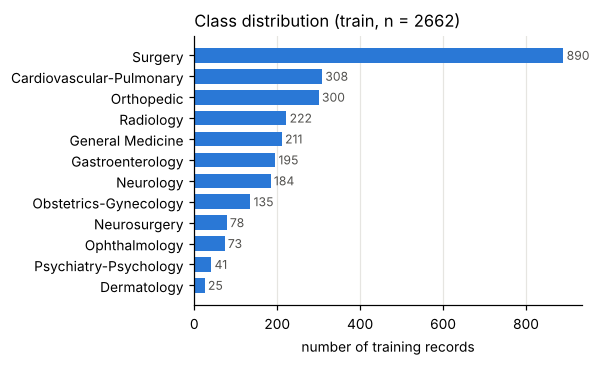

In [7]:
counts = train_raw["medical_specialty"].value_counts()
dist = pd.DataFrame({"count": counts, "percent": (100 * counts / counts.sum()).round(1)})
display(dist)
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f} : 1")
print(f"Majority-class baseline accuracy: {counts.max() / counts.sum():.1%}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
c = counts.sort_values()
ax.barh(c.index, c.values, color=BLUE, height=0.7)
for y, v in enumerate(c.values):
    ax.text(v + 8, y, str(v), va="center", fontsize=8, color="#52514e")
ax.set_xlabel("number of training records"); ax.grid(axis="y", visible=False)
ax.set_title("Class distribution (train, n = %d)" % len(train_raw), loc="left")
fig.tight_layout(); fig.savefig(FIG_DIR / "class_distribution.pdf"); plt.show()

### 2.2 Missing / empty fields (train vs. test)

In [8]:
def empty_table(df):
    return pd.DataFrame({"empty": (df[TEXT_COLS] == "").sum(),
                         "% empty": (100 * (df[TEXT_COLS] == "").mean()).round(1)})

pd.concat({"train": empty_table(train_raw), "test": empty_table(test_raw)}, axis=1)

train          test        
              empty % empty empty % empty
description       1     0.0     2     0.5
sample_name       0     0.0     9     2.2
transcription    24     0.9    11     2.7
keywords        443    16.6    89    21.8

`keywords` is missing for ~17% of train and ~22% of test records — relevant because of observation 3.2.

### 2.3 Text lengths

,count,mean,std,min,50%,90%,max
description,2662.0,18.9,12.2,0.0,16.0,36.0,76.0
sample_name,2662.0,3.8,1.4,1.0,4.0,6.0,8.0
transcription,2662.0,452.9,310.1,0.0,387.0,861.0,2454.0
keywords,2662.0,22.7,21.5,0.0,19.0,40.0,118.0


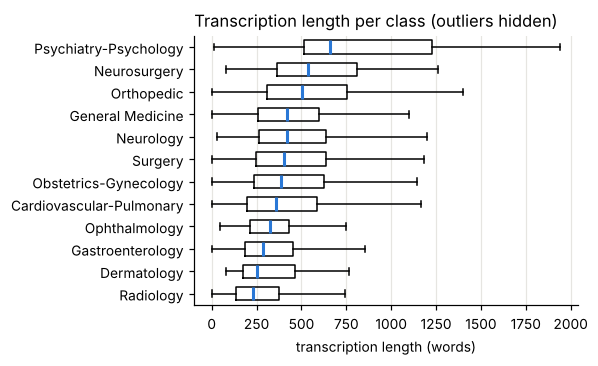

In [9]:
lens = pd.DataFrame({c: train_raw[c].str.split().str.len() for c in TEXT_COLS})
display(lens.describe(percentiles=[.5, .9]).T.round(1))

order = lens.groupby(train_raw["medical_specialty"])["transcription"].median().sort_values().index
fig, ax = plt.subplots(figsize=(5.5, 3.4))
import warnings
with warnings.catch_warnings():  # `vert` is deprecated in matplotlib >= 3.11 but works everywhere
    warnings.simplefilter("ignore")
    ax.boxplot([lens.loc[train_raw["medical_specialty"] == l, "transcription"] for l in order],
               vert=False, showfliers=False, widths=0.6, medianprops=dict(color=BLUE, linewidth=2))
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_xlabel("transcription length (words)"); ax.grid(axis="y", visible=False)
ax.set_title("Transcription length per class (outliers hidden)", loc="left")
fig.tight_layout(); fig.savefig(FIG_DIR / "length_per_class.pdf"); plt.show()

Transcriptions are long (median ≈ 400 words; Radiology reports are shortest, Psychiatry the longest). Relevant for transformer models with a 512-token limit: most documents will be truncated, so *which* part is kept matters (see section-crop augmentation in §6).

## 3. Observations (patterns & anomalies)

### 3.1 The same report appears several times **with different labels**

In [10]:
has_t = train_raw[train_raw["transcription"] != ""]
dup = has_t[has_t.duplicated("transcription", keep=False)]
groups = dup.groupby("transcription")["medical_specialty"]
n_groups = groups.ngroups
conflicting = (groups.nunique() > 1).sum()

print(f"{len(dup)} of {len(train_raw)} records ({len(dup)/len(train_raw):.0%}) share their "
      f"transcription with at least one other record")
print(f"{n_groups} groups of identical transcriptions, {conflicting} of them with DIFFERENT labels")

pairs = groups.agg(lambda s: " + ".join(sorted(set(s)))).value_counts().head(10)
display(pairs.rename("groups").to_frame())

1532 of 2662 records (58%) share their transcription with at least one other record
732 groups of identical transcriptions, 731 of them with DIFFERENT labels


,groups
medical_specialty,
Cardiovascular-Pulmonary + Surgery,123
Orthopedic + Surgery,122
Gastroenterology + Surgery,97
Obstetrics-Gynecology + Surgery,67
Cardiovascular-Pulmonary + Radiology,44
Ophthalmology + Surgery,42
Neurology + Radiology,38
Neurosurgery + Orthopedic + Surgery,26
Orthopedic + Radiology,22


In [11]:
# One concrete example
example = dup[dup["transcription"] == groups.size().idxmax()]
display(example[["medical_specialty", "sample_name", "description"]])

,medical_specialty,sample_name,description
743,Neurology,Lumbar Discogram,"Lumbar discogram L2-3, L3-4, L4-5, and L5-S1. Low back pain."
1368,Orthopedic,Lumbar Discogram,"Lumbar discogram L2-3, L3-4, L4-5, and L5-S1. Low back pain."
1611,Radiology,Lumbar Discogram,"Lumbar discogram L2-3, L3-4, L4-5, and L5-S1. Low back pain."
2509,Surgery,Lumbar Discogram,"Lumbar discogram L2-3, L3-4, L4-5, and L5-S1. Low back pain."


In [12]:
# Upper bound for any classifier that only reads the text fields (no keywords):
# within a group of k identical texts, at most one label can be right.
key = train_raw["transcription"].where(train_raw["transcription"] != "", train_raw["description"])
ceiling = key.nunique() / len(train_raw)
print(f"Accuracy ceiling for text-only models on train: ~{ceiling:.0%}")

Accuracy ceiling for text-only models on train: ~70%


**Interpretation.** The source website (mtsamples) files one report under *several* specialties — e.g. an orthopaedic operation is listed under both *Surgery* and *Orthopedic*. The task is really **multi-label**, flattened into single-label rows. Consequences:
* Without the keywords, no model can exceed ~70% accuracy on such data; *Surgery* will be confused with every procedural specialty.
* **A random train/validation split leaks**: the same text ends up on both sides with different labels. We must split with `StratifiedGroupKFold` using `group_ids()` (identical texts → same fold).

### 3.2 The first keyword **is** the label

In [13]:
kw1 = train_raw["keywords"].map(first_keyword)
has_kw = train_raw["keywords"] != ""
match = (kw1 == train_raw["medical_specialty"].map(LABEL_TO_KEYWORD))[has_kw]
print(f"records with keywords: {has_kw.sum()} | first keyword == label: {match.mean():.1%}")

test_kw1 = test_raw["keywords"].map(first_keyword)
print("\nFirst keyword in the TEST set:")
print(test_kw1.replace("", "<no keywords>").value_counts().to_string())

# Within duplicate groups the keywords differ exactly where the label differs:
print("\nexample:")
display(example[["medical_specialty", "keywords"]].assign(keywords=lambda d: d.keywords.str[:70]))

records with keywords: 2219 | first keyword == label: 100.0%

First keyword in the TEST set:
keywords
surgery                       135
<no keywords>                  89
cardiovascular / pulmonary     32
radiology                      32
orthopedic                     25
gastroenterology               24
neurology                      17
obstetrics / gynecology        15
general medicine               12
neurosurgery                   11
ophthalmology                   8
psychiatry / psychology         5
dermatology                     4

example:


,medical_specialty,keywords
743,Neurology,"neurology, back pain, c-arm, fluoroscopic projections, disc space, lum"
1368,Orthopedic,"orthopedic, back pain, c-arm, fluoroscopic projections, disc space, lu"
1611,Radiology,"radiology, back pain, c-arm, fluoroscopic projections, disc space, lum"
2509,Surgery,"surgery, back pain, c-arm, fluoroscopic projections, disc space, lumba"


**Interpretation.** `keywords` starts with the specialty name in 100% of the 2,219 training records that have keywords, and the test set follows the same format (78% of test records have keywords). This is *target leakage* built into the dataset: a one-line regex rule labels ~78% of the test set. It is also the **only** field that tells the duplicates of §3.1 apart.

How to use this honestly is a design decision for the paper (see §8) — it can even become the research question.

### 3.3 Train/test overlap

In [14]:
train_texts = set(train_raw["transcription"]) - {""}
in_train = test_raw["transcription"].isin(train_texts) & (test_raw["transcription"] != "")
print(f"{in_train.sum()} of {(test_raw['transcription'] != '').sum()} test transcriptions "
      f"appear verbatim in train ({in_train.mean():.0%})")

240 of 398 test transcriptions appear verbatim in train (59%)


Given §3.1, a test copy of a training text most likely has a **different** label from its training copy (the duplicates are the *other* specialties the same report was filed under). A nearest-neighbour model that just copies the training label would be systematically wrong on these — worth discussing in the error analysis.

### 3.4 Structure inside the transcriptions
Two regularities are invisible in the DataFrame view but obvious in the raw text:
* line breaks of the original report were flattened into `.,` (median 9 per document);
* reports are organised in **upper-case section headers** (`PREOPERATIVE DIAGNOSIS:`, `IMPRESSION:`, ...), and *which* headers appear reveals the document type.

most frequent headers: [('ANESTHESIA', 839), ('PROCEDURE', 776), ('PREOPERATIVE DIAGNOSIS', 766), ('POSTOPERATIVE DIAGNOSIS', 699), ('COMPLICATIONS', 522), ('IMPRESSION', 438), ('FINDINGS', 431), ('ESTIMATED BLOOD LOSS', 420), ('PROCEDURE PERFORMED', 415), ('POSTOPERATIVE DIAGNOSES', 340), ('HISTORY OF PRESENT ILLNESS', 298), ('PREOPERATIVE DIAGNOSES', 298), ('DESCRIPTION OF PROCEDURE', 276), ('EXAM', 266), ('INDICATIONS', 263)]


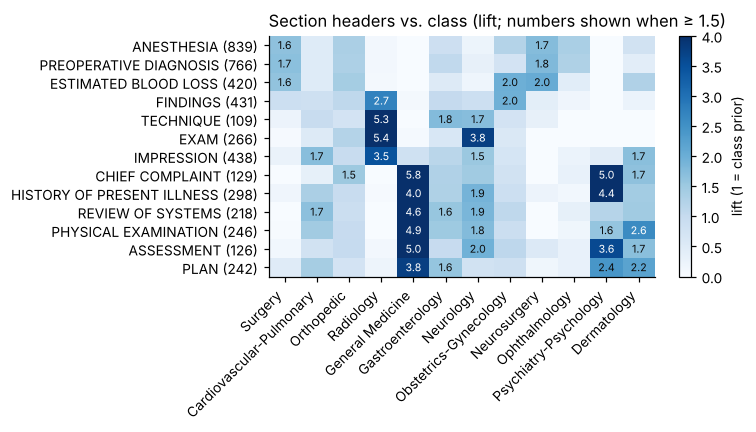

In [15]:
train_raw["headers"] = train_raw["transcription"].map(lambda t: {h.strip() for h in SECTION_RE.findall(t)})
header_counts = Counter(h for hs in train_raw["headers"] for h in hs)
print("most frequent headers:", header_counts.most_common(15))

# A readable selection: operative-note, imaging-report and consultation headers
HEADERS = ["ANESTHESIA", "PREOPERATIVE DIAGNOSIS", "ESTIMATED BLOOD LOSS", "FINDINGS",
           "TECHNIQUE", "EXAM", "IMPRESSION", "CHIEF COMPLAINT", "HISTORY OF PRESENT ILLNESS",
           "REVIEW OF SYSTEMS", "PHYSICAL EXAMINATION", "ASSESSMENT", "PLAN"]
HEADERS = [h for h in HEADERS if header_counts[h] >= 30]
prior = train_raw["medical_specialty"].value_counts(normalize=True)
# lift = P(class | header present) / P(class); 1 = no association
lift = pd.DataFrame({h: train_raw.loc[train_raw["headers"].map(lambda s: h in s), "medical_specialty"]
                     .value_counts(normalize=True) for h in HEADERS}).T.fillna(0)[counts.index] / prior[counts.index]

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(lift.values, cmap="Blues", vmin=0, vmax=4, aspect="auto")
ax.set_xticks(range(len(lift.columns)), lift.columns, rotation=45, ha="right")
ax.set_yticks(range(len(lift.index)), [f"{h} ({header_counts[h]})" for h in lift.index])
for (r, c), v in np.ndenumerate(lift.values):
    if v >= 1.5:
        ax.text(c, r, f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="white" if v > 2.5 else "#0b0b0b")
ax.grid(False); fig.colorbar(im, ax=ax, label="lift (1 = class prior)")
ax.set_title("Section headers vs. class (lift; numbers shown when ≥ 1.5)", loc="left")
fig.tight_layout(); fig.savefig(FIG_DIR / "headers_vs_class.pdf"); plt.show()

Each cell says how much more frequent a class is among documents containing that header than overall. `ANESTHESIA`/`ESTIMATED BLOOD LOSS` → operative notes (Surgery and the surgical specialties), `EXAM`/`IMPRESSION` → imaging reports (*Radiology*), `CHIEF COMPLAINT`/`HISTORY OF PRESENT ILLNESS` → consultations (*General Medicine*, *Psychiatry-Psychology*). Surgery itself has a lift of only ~1.6 for the operative headers because the surgical specialties use the same template — another view of observation 3.1. The header set is a cheap feature, and also the basis of the **section-crop** augmentation.

### 3.5 Other artefacts

In [16]:
boiler = train_raw["keywords"].str.contains(r"NOTE\s*,?\s*:\s*These\s*transcribed", regex=True)
print(f"website disclaimer glued to the last keyword: {boiler.sum()} train records")
print("   e.g.", train_raw.loc[boiler, "keywords"].iloc[0][-160:], "\n")

numbered = train_raw["sample_name"].str.contains(r"-\s*\d+\s*$", regex=True)
print(f"sample_name with a numeric suffix ('Discharge Summary - 12'): {numbered.mean():.0%}")
print("most common sample names:",
      train_raw["sample_name"].str.replace(r"\s*-\s*\d+\s*$", "", regex=True).value_counts().head(5).to_dict())

desc_repeat = (train_raw["description"].str.lower().str[:40]
               .pipe(lambda s: [d in t.lower() for d, t in zip(s, train_raw["transcription"])]))
print(f"description is copied from the transcription: {np.mean(desc_repeat):.0%}")

website disclaimer glued to the last keyword: 150 train records
   e.g. have beenchanged (or removed) to keep confidentiality. Any resemblance of any type of name or date orplace or anything else to real world is purely incidental., 

sample_name with a numeric suffix ('Discharge Summary - 12'): 32%
most common sample names: {'Gen Med Consult': 43, 'Colonoscopy': 37, 'Anterior Cervical Discectomy & Fusion': 25, 'Cardiac Catheterization': 24, 'Esophagogastroduodenoscopy': 22}
description is copied from the transcription: 44%


* The disclaimer is the same for every class → pure noise, removed in cleaning.
* Generic sample names (*Discharge Summary*, *Consult*, *Template*) carry little information; procedure names (*Craniotomy - Temporal*) carry a lot.
* The description frequently repeats the first sentence of the transcription — the two fields are not independent views.

### 3.6 Most discriminative words per class

In [17]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

cv = CountVectorizer(stop_words="english", min_df=5, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
X = cv.fit_transform(train_raw["transcription"])
vocab = np.array(cv.get_feature_names_out())
top_words = {}
for lab in counts.index:
    scores, _ = chi2(X, train_raw["medical_specialty"] == lab)
    top_words[lab] = ", ".join(vocab[np.argsort(np.nan_to_num(scores))[::-1][:8]])
pd.Series(top_words, name="top χ² words (transcription)").to_frame()

,top χ² words (transcription)
Surgery,"procedure, history, placed, incision, anesthesia, removed, normal, using"
Cardiovascular-Pulmonary,"artery, coronary, pulmonary, chest, ventricular, atrial, heart, cardiac"
Orthopedic,"knee, joint, fracture, tendon, tourniquet, medial, pain, foot"
Radiology,"patient, images, exam, unremarkable, procedure, placed, velocity, motor"
General Medicine,"negative, history, denies, nontender, regular, clear, sounds, heent"
Gastroenterology,"colon, stomach, gallbladder, esophagus, colonoscopy, cecum, duct, scope"
Neurology,"gait, mri, unremarkable, brain, sensory, motor, reflexes, weakness"
Obstetrics-Gynecology,"uterus, uterine, cervix, vaginal, fetal, pelvic, pregnancy, delivery"
Neurosurgery,"dura, bone, tumor, cervical, decompression, discectomy, screws, disk"
Ophthalmology,"eye, lens, chamber, lid, intraocular, cataract, corneal, phacoemulsification"


Note how *Surgery* has the weakest, most generic vocabulary (procedure words shared with every surgical specialty) while small classes such as *Ophthalmology* or *Dermatology* have very specific terms — small but easy classes, vs. a large but vague one.

> Note: we did **not** remove stop words for modelling. Words like *no*, *not*, *without*, *left*/*right* matter in clinical text (the project statement warns about this too). They are only filtered here to make the χ² table readable.

## 4. Regex: where it helps (and where it doesn't)

Should the analysis be done with regex? Short answer: **use regex for the *structure* of the text, pandas/scikit-learn for the *statistics*.**

| task | best tool | why |
|---|---|---|
| detecting / repairing the broken CSV lines | plain string ops on raw lines | the problem is in the *file*, not the text |
| counts, distributions, duplicates, missing values | pandas | vectorised, readable, less error-prone |
| section headers, `.,` line breaks, disclaimer, `- 12` suffixes, first keyword | **regex** | fixed, well-defined surface patterns |
| "which words characterise each class" | `CountVectorizer` + χ² / TF-IDF | statistical, not a pattern |
| negation, abbreviations, synonyms | a dictionary or a model | regex gets brittle fast |

All regexes are defined once in `src/data.py` (`BOILERPLATE_RE`, `NEWLINE_RE`, `SECTION_RE`, `SAMPLE_NUM_RE`) so train and test get the same treatment. Regex-based **features** (e.g. the header set, or a rule on the first keyword) are also legitimate *models* to compare against in the paper.

## 5. Cleaning (applied identically to train and test)
`clean_df` removes the disclaimer, turns `.,` back into line breaks, normalises whitespace and strips the numeric suffix of `sample_name`. It does **not** lowercase, stem or remove stop words — those are model choices made inside each pipeline.

In [18]:
train = clean_df(train_raw.drop(columns="headers"))
test = clean_df(test_raw)

i = boiler.idxmax()
print("BEFORE keywords:", train_raw.loc[i, "keywords"][-150:])
print("AFTER  keywords:", train.loc[i, "keywords"][-150:], "\n")
print("BEFORE transcription:", train_raw.loc[0, "transcription"][:230])
print("AFTER  transcription:", train.loc[0, "transcription"][:230])

train["group"] = group_ids(train)
Path("outputs").mkdir(exist_ok=True)
train.to_csv("outputs/train_clean.csv", index=False)
test.to_csv("outputs/test_clean.csv", index=False)

BEFORE keywords: hanged (or removed) to keep confidentiality. Any resemblance of any type of name or date orplace or anything else to real world is purely incidental.,
AFTER  keywords: apacity, pulmonary function test, shortness of breath, pulmonary function studies, pulmonary function, function, biopsy, lung, interstitial, pulmonary 

BEFORE transcription: REASON FOR REFERRAL:  Chest pain, possible syncopal spells.,She is a very pleasant 31-year-old mother of two children with ADD.,She was doing okay until January of 2009 when she had a partial hysterectomy.  Since then she just say
AFTER  transcription: REASON FOR REFERRAL: Chest pain, possible syncopal spells.
She is a very pleasant 31-year-old mother of two children with ADD.
She was doing okay until January of 2009 when she had a partial hysterectomy. Since then she just says 


## 6. Data augmentation

The task template makes augmentation mandatory. The main motivation from the data is the **36:1 class imbalance** (§2.1) and the missing keywords in 22% of the test set (§2.2). Strategies implemented in `src/augmentation.py`:

| # | strategy | idea | justification from the data |
|---|---|---|---|
| 1 | **EDA** (Wei & Zou, 2019) | random swap / deletion / insertion; WordNet synonyms if available | generic, model-agnostic baseline |
| 2 | **Abbreviation swap** | `MRI` ↔ `magnetic resonance imaging`, `EGD` ↔ ... | clinical notes mix both forms; WordNet knows little medicine |
| 3 | **Section crop** | keep a random subset of the report's sections | reports are sectioned (§3.4); creates shorter but coherent documents, also mimics 512-token truncation |
| 4 | **Field dropout** | blank `keywords` / `description` / `sample_name` at random | 22% of test rows have no keywords; forces the model to also learn from the text |
| 5 | Back-translation (optional) | en → fr → en with MarianMT | paraphrases; slow and may corrupt medical terms |

Rules: negations and laterality (*no, not, without, left, right*) are never deleted or replaced; augmentation is applied **only to the training folds, after splitting**.

> To enable WordNet synonyms on your machine: `import nltk; nltk.download("wordnet")`.

### 6.1 What each strategy produces

In [19]:
import random
rng = random.Random(SEED)
row = train[train["medical_specialty"] == "Dermatology"].iloc[3]
text = row["transcription"]

print("ORIGINAL:\n", text[:500], "\n")
print("EDA (one random op):\n", aug.eda(text, rng)[:500], "\n")
abbr_row = train[train["description"].str.contains(r"\b(?:MRI|EGD|CT|CABG|COPD)\b", regex=True)].iloc[0]
print("ABBREVIATION SWAP (description, p=1):\n", abbr_row["description"], "\n->",
      aug.abbreviation_swap(abbr_row["description"], random.Random(1), p=1.0), "\n")
print("SECTION CROP:\n", aug.section_crop(text, rng)[:500], "\n")
print("FIELD DROPOUT:\n", aug.field_dropout(row, random.Random(3))[["description", "sample_name", "keywords"]].to_dict())

ORIGINAL:
 SUBJECTIVE: The patient is a 49-year-old white female, established patient to Dermatology, last seen in the office on 08/10/2004. She comes in today for reevaluation of her acne plus she has had what she calls a rash for the past two months now on her chest, stomach, neck, and back. On examination, this is a flaring of her acne with small folliculitis lesions. The patient has been taking amoxicillin 500 mg b.i.d. and using Tazorac cream 0.1, and her face is doing well, but she has been out of he 

EDA (one random op):
 SUBJECTIVE: The patient b.i.d. is a 49-year-old white female, established patient to Dermatology, last the seen in chest, the office on 08/10/2004. stated She comes in today for reevaluation of her acne plus she has stated had what she calls a rash for the past two months now on with her chest, stomach, neck, on and back. On examination, the this is a flaring of last her acne with small folliculitis lesions. The patient has been taking amoxicillin 500 mg b.i.d

In [20]:
# Optional back-translation (downloads ~600 MB of models the first time)
RUN_BACKTRANSLATION = False
if RUN_BACKTRANSLATION:
    print(aug.back_translate([row["description"]], pivot="fr"))

### 6.2 Rebalancing the training set

In [21]:
balanced = aug.oversample_minority(train, seed=SEED)  # every class up to the median class size
comparison = pd.DataFrame({"original": train["medical_specialty"].value_counts(),
                           "after augmentation": balanced["medical_specialty"].value_counts()})
display(comparison)
print("total:", len(train), "->", len(balanced))

,original,after augmentation
medical_specialty,,
Cardiovascular-Pulmonary,308,308
Dermatology,25,189
Gastroenterology,195,195
General Medicine,211,211
Neurology,184,189
Neurosurgery,78,189
Obstetrics-Gynecology,135,189
Ophthalmology,73,189
Orthopedic,300,300


total: 2662 -> 3260


Only classes below the median size (Neurosurgery, Ophthalmology, Psychiatry-Psychology, Dermatology, Obstetrics-Gynecology) are topped up; nothing is removed from Surgery. Other options worth comparing in the paper: up-sample to the *largest* class, or use class weights instead of new data.

## 7. Sanity check: leak-free evaluation

5-fold `StratifiedGroupKFold` (identical texts stay in the same fold), reporting accuracy, macro-F1 and the **minimum per-class F1** (the automatic evaluation requires accuracy > 49% *and* every class F1 ≥ 25%).

Compared:
* **official baseline** — TF-IDF on `description`, lowercase + Porter stemming, Multinomial NB;
* TF-IDF (1–2-grams) + linear SVM on the transcription, without / with augmentation;
* the same SVM on all fields concatenated (keywords included).

This is just a check that the data pipeline is sound — model selection belongs in the next notebook.

In [22]:
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

stemmer = PorterStemmer()
_tok = TfidfVectorizer(lowercase=True).build_analyzer()
def stem_analyzer(text):
    return [stemmer.stem(w) for w in _tok(text)]

def baseline():
    return make_pipeline(TfidfVectorizer(analyzer=stem_analyzer), MultinomialNB())

def svm():
    return make_pipeline(TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2, max_features=50_000),
                         LinearSVC(C=0.5, class_weight="balanced"))

FIELDS = {
    "description": lambda d: d["description"],
    "transcription": lambda d: d["transcription"],
    "all fields": lambda d: d["description"] + " " + d["sample_name"] + " " + d["transcription"] + " " + d["keywords"],
}

def cross_validate(make_model, field, augment=False, n_splits=5):
    y, X_text = train["medical_specialty"].values, FIELDS[field]
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=0)
    scores = []
    for tr_idx, va_idx in cv.split(train, y, train["group"]):
        tr = train.iloc[tr_idx]
        if augment:
            tr = aug.oversample_minority(tr, seed=SEED)  # augment the training fold only
        model = make_model().fit(X_text(tr), tr["medical_specialty"])
        pred = model.predict(X_text(train.iloc[va_idx]))
        f1 = f1_score(y[va_idx], pred, labels=LABELS, average=None, zero_division=0)
        scores.append((accuracy_score(y[va_idx], pred), f1.mean(), f1.min()))
    return dict(zip(["accuracy", "macro-F1", "min class F1"], np.mean(scores, axis=0).round(3)))

results = pd.DataFrame({
    "baseline NB (description)": cross_validate(baseline, "description"),
    "SVM (transcription)": cross_validate(svm, "transcription"),
    "SVM (transcription) + augmentation": cross_validate(svm, "transcription", augment=True),
    "SVM (all fields)": cross_validate(svm, "all fields"),
}).T
results

,accuracy,macro-F1,min class F1
baseline NB (description),0.413,0.152,0.000
SVM (transcription),0.572,0.602,0.454
SVM (transcription) + augmentation,0.577,0.605,0.472
SVM (all fields),0.692,0.707,0.549


**Reading the numbers**
* The official baseline is ~41% under a leak-free split (below the 49% bar) and collapses to the majority classes: min class F1 = 0.
* Text-only SVM ≈ 57%, close-ish to the ~70% ceiling of §3.1; it already satisfies the per-class F1 ≥ 25% constraint.
* Augmentation gives only a **small gain** for a linear TF-IDF model (≈ +0.5 pt accuracy, +2 pt on the weakest class) — probably within fold-to-fold noise, since balanced class weights already compensate for imbalance and n-gram counts barely change. Expect it to matter more for neural models; to claim an effect, repeat with several seeds and report mean ± std per class.
* Adding the fields (mainly `keywords`) jumps to ~69%, confirming §3.2.

## 8. Summary — paper-ready findings

**Data Analysis (≥ 2 concrete observations)**
1. *Corrupted CSV*: four blocks per file where a field was truncated at ≈ 32,758 characters (Excel's cell limit) left an unbalanced quote; a standard CSV parser merges 46 training records into others and produces 3 bogus labels. We repair it with a line-based parser (2,662 training records, 409 test records).
2. *Duplicates with conflicting labels*: 58% of training records share their transcription with another record, and in 731 of 732 such groups the labels differ (most often *Surgery* + an organ specialty). The task is effectively multi-label; text-only accuracy is capped at ~70%, and splits must be grouped.
3. *Label leakage through keywords*: the first keyword equals the label in 100% of training records that have keywords; 78% of the test records have keywords.
4. *Imbalance*: Surgery has 890 records (33%) vs. 25 for Dermatology (36:1).
5. *Structure*: section headers identify the document type (operative note / imaging report / consultation), which maps onto Surgery / Radiology / General Medicine.
6. 59% of test transcriptions occur verbatim in train — most likely under a different specialty.

**Data Augmentation** — section crop + abbreviation swap + EDA + field dropout, used to bring every class up to the median class size, applied only inside training folds.

**Possible research questions** (the introduction must state one):
* *How much of the achievable performance comes from metadata leakage (keywords) versus the clinical text itself?* — compare keyword-rule, text-only and all-field models.
* *Does domain-aware augmentation (section crop, abbreviation swap) help minority classes more than generic EDA, for classical vs. transformer models?*